<a href="https://colab.research.google.com/github/ahmedhasan-27/shiftsmart-ai/blob/main/06_decision_trees.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Chapter 6 – Decision Trees**

Name - Mohammed Ahmed Ul Hasan Kalimi Syed

Module 4 Assignment on Decision Trees

# Setup

This project requires Python 3.7 or above:

In [1]:
import sys

assert sys.version_info >= (3, 7)

It also requires Scikit-Learn ≥ 1.0.1:

In [2]:
from packaging import version
import sklearn

assert version.parse(sklearn.__version__) >= version.parse("1.0.1")

As we did in previous chapters, let's define the default font sizes to make the figures prettier:

In [3]:
import matplotlib.pyplot as plt

plt.rc('font', size=14)
plt.rc('axes', labelsize=14, titlesize=14)
plt.rc('legend', fontsize=14)
plt.rc('xtick', labelsize=10)
plt.rc('ytick', labelsize=10)

And let's create the `images/decision_trees` folder (if it doesn't already exist), and define the `save_fig()` function which is used through this notebook to save the figures in high-res for the book:

In [4]:
from pathlib import Path

IMAGES_PATH = Path() / "images" / "decision_trees"
IMAGES_PATH.mkdir(parents=True, exist_ok=True)

def save_fig(fig_id, tight_layout=True, fig_extension="png", resolution=300):
    path = IMAGES_PATH / f"{fig_id}.{fig_extension}"
    if tight_layout:
        plt.tight_layout()
    plt.savefig(path, format=fig_extension, dpi=resolution)

# Training and Visualizing a Decision Tree

In [5]:
from sklearn.datasets import load_iris
from sklearn.tree import DecisionTreeClassifier

iris = load_iris(as_frame=True)
X_iris = iris.data[["petal length (cm)", "petal width (cm)"]].values
y_iris = iris.target

tree_clf = DecisionTreeClassifier(max_depth=2, random_state=42)
tree_clf.fit(X_iris, y_iris)

DecisionTreeClassifier(max_depth=2, random_state=42)

# Exercise solutions

## 1. to 6.

1. The depth of a well-balanced binary tree containing _m_ leaves is equal to log₂(_m_), rounded up. log₂ is the binary log; log₂(_m_) = log(_m_) / log(2). A binary Decision Tree (one that makes only binary decisions, as is the case with all trees in Scikit-Learn) will end up more or less well balanced at the end of training, with one leaf per training instance if it is trained without restrictions. Thus, if the training set contains one million instances, the Decision Tree will have a depth of log₂(10<sup>6</sup>) ≈ 20 (actually a bit more since the tree will generally not be perfectly well balanced).
2. A node's Gini impurity is generally lower than its parent's. This is due to the CART training algorithm's cost function, which splits each node in a way that minimizes the weighted sum of its children's Gini impurities. However, it is possible for a node to have a higher Gini impurity than its parent, as long as this increase is more than compensated for by a decrease in the other child's impurity. For example, consider a node containing four instances of class A and one of class B. Its Gini impurity is 1 – (1/5)² – (4/5)² = 0.32. Now suppose the dataset is one-dimensional and the instances are lined up in the following order: A, B, A, A, A. You can verify that the algorithm will split this node after the second instance, producing one child node with instances A, B, and the other child node with instances A, A, A. The first child node's Gini impurity is 1 – (1/2)² – (1/2)² = 0.5, which is higher than its parent's. This is compensated for by the fact that the other node is pure, so its overall weighted Gini impurity is 2/5 × 0.5 + 3/5 × 0 = 0.2, which is lower than the parent's Gini impurity.
3. If a Decision Tree is overfitting the training set, it may be a good idea to decrease `max_depth`, since this will constrain the model, regularizing it.
4. Decision Trees don't care whether or not the training data is scaled or centered; that's one of the nice things about them. So if a Decision Tree underfits the training set, scaling the input features will just be a waste of time.
5. The computational complexity of training a Decision Tree is _O_(_n_ × _m_ log₂(_m_)). So if you multiply the training set size by 10, the training time will be multiplied by _K_ = (_n_ × 10 _m_ × log₂(10 _m_)) / (_n_ × _m_ × log₂(_m_)) = 10 × log₂(10 _m_) / log₂(_m_). If _m_ = 10<sup>6</sup>, then _K_ ≈ 11.7, so you can expect the training time to be roughly 11.7 hours.
6. If the number of features doubles, then the training time will also roughly double.

## 7.

_Exercise: train and fine-tune a Decision Tree for the moons dataset._

a. Generate a moons dataset using `make_moons(n_samples=10000, noise=0.4)`.

Adding `random_state=42` to make this notebook's output constant:

In [6]:
from sklearn.datasets import make_moons

X_moons, y_moons = make_moons(n_samples=10000, noise=0.4, random_state=42)

b. Split it into a training set and a test set using `train_test_split()`.

In this specific exercise, we train Decision Tree (and later Random Forest ensemble) on X_train / y_train and then measure its final accuracy on the untouched test set (X_test / y_test).

The Decision Trees trained on the smaller subsets perform worse (averaging around 80% accuracy compared to ~86% for the main model) for a few key reasons:

* **Less Training Data:** Each mini-set contains only 100 instances, compared to the 8,000 instances in the main training set (`X_train`). With significantly fewer examples to learn from, the individual trees have a harder time capturing the complex, underlying patterns of the moons dataset.
* **Higher Variance and Instability:** Decision trees are notoriously sensitive to the specific data points they are trained on (high variance). Small, random variations in a 100-sample subset can lead to radically different tree structures and split decisions, making individual trees less reliable on unseen test data.

This performance drop of the individual trees is actually a feature, not a bug, in ensemble learning. When you combine many diverse, slightly weaker models through a majority vote (as done in the subsequent steps to form a Random Forest), their individual errors cancel each other out, resulting in a stronger overall prediction (yielding ~87.3% accuracy).

In [7]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X_moons, y_moons,
                                                    test_size=0.2,
                                                    random_state=42)

c. Use grid search with cross-validation (with the help of the `GridSearchCV` class) to find good hyperparameter values for a `DecisionTreeClassifier`. Hint: try various values for `max_leaf_nodes`.

In [8]:
from sklearn.model_selection import GridSearchCV

params = {
    'max_leaf_nodes': list(range(2, 100)),
    'max_depth': list(range(1, 7)),
    'min_samples_split': [2, 3, 4]
}
grid_search_cv = GridSearchCV(DecisionTreeClassifier(random_state=42),
                              params,
                              cv=3)

grid_search_cv.fit(X_train, y_train)

GridSearchCV(cv=3, estimator=DecisionTreeClassifier(random_state=42),
             param_grid={'max_depth': [1, 2, 3, 4, 5, 6],
                         'max_leaf_nodes': [2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12,
                                            13, 14, 15, 16, 17, 18, 19, 20, 21,
                                            22, 23, 24, 25, 26, 27, 28, 29, 30,
                                            31, ...],
                         'min_samples_split': [2, 3, 4]})

In [9]:
grid_search_cv.best_estimator_

DecisionTreeClassifier(max_depth=6, max_leaf_nodes=17, random_state=42)

d. Train it on the full training set using these hyperparameters, and measure your model's performance on the test set. You should get roughly 85% to 87% accuracy.

the best-performing hyperparameters found by the grid search:

max_depth: 6

max_leaf_nodes: 17

random_state: 42

By default, `GridSearchCV` trains the best model found on the whole training set (you can change this by setting `refit=False`), so we don't need to do it again. We can simply evaluate the model's accuracy:

In [10]:
from sklearn.metrics import accuracy_score

y_pred = grid_search_cv.predict(X_test)
accuracy_score(y_test, y_pred)

0.8595

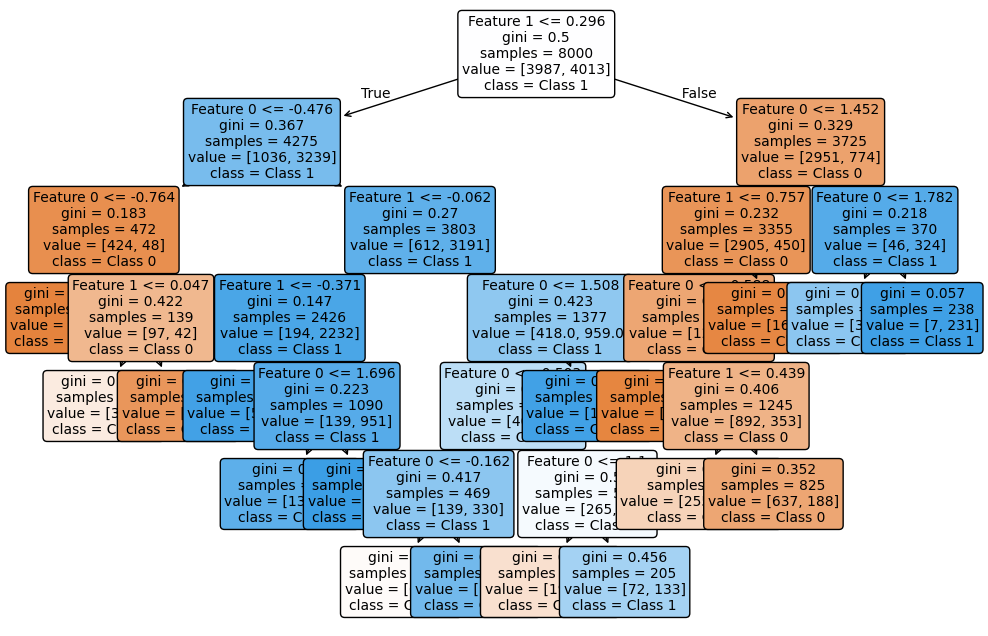

In [20]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 8))
plot_tree(grid_search_cv.best_estimator_,
          feature_names=["Feature 0", "Feature 1"],
          class_names=["Class 0", "Class 1"],
          filled=True,
          rounded=True,
          fontsize=10)
plt.show()

## 8.

_Exercise: Grow a forest._

a. Continuing the previous exercise, generate 1,000 subsets of the training set, each containing 100 instances selected randomly. Hint: you can use Scikit-Learn's `ShuffleSplit` class for this.

In [11]:
from sklearn.model_selection import ShuffleSplit

n_trees = 1000
n_instances = 100

mini_sets = []

rs = ShuffleSplit(n_splits=n_trees, test_size=len(X_train) - n_instances,
                  random_state=42)

for mini_train_index, mini_test_index in rs.split(X_train):
    X_mini_train = X_train[mini_train_index]
    y_mini_train = y_train[mini_train_index]
    mini_sets.append((X_mini_train, y_mini_train))

b. Train one Decision Tree on each subset, using the best hyperparameter values found above. Evaluate these 1,000 Decision Trees on the test set. Since they were trained on smaller sets, these Decision Trees will likely perform worse than the first Decision Tree, achieving only about 80% accuracy.

In [15]:
import numpy as np

In [16]:
from sklearn.base import clone

forest = [clone(grid_search_cv.best_estimator_) for _ in range(n_trees)]

accuracy_scores = []

for tree, (X_mini_train, y_mini_train) in zip(forest, mini_sets):
    tree.fit(X_mini_train, y_mini_train)

    y_pred = tree.predict(X_test)
    accuracy_scores.append(accuracy_score(y_test, y_pred))

np.mean(accuracy_scores)

np.float64(0.8056605)

c. Now comes the magic. For each test set instance, generate the predictions of the 1,000 Decision Trees, and keep only the most frequent prediction (you can use SciPy's `mode()` function for this). This gives you _majority-vote predictions_ over the test set.

In [17]:
Y_pred = np.empty([n_trees, len(X_test)], dtype=np.uint8)

for tree_index, tree in enumerate(forest):
    Y_pred[tree_index] = tree.predict(X_test)

In [18]:
from scipy.stats import mode

y_pred_majority_votes, n_votes = mode(Y_pred, axis=0)

d. Evaluate these predictions on the test set: you should obtain a slightly higher accuracy than your first model (about 0.5 to 1.5% higher). Congratulations, you have trained a Random Forest classifier!

In [19]:
accuracy_score(y_test, y_pred_majority_votes.reshape([-1]))

0.873

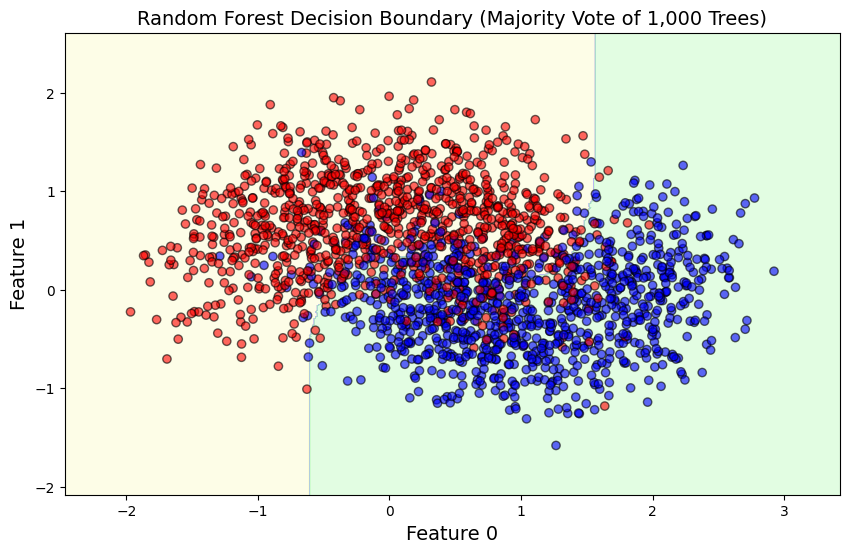

In [21]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

def plot_decision_boundary(X, y, y_pred_fn):
    # Set up mesh grid
    x1_min, x1_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    x2_min, x2_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx1, xx2 = np.meshgrid(np.linspace(x1_min, x1_max, 500),
                           np.linspace(x2_min, x2_max, 500))

    # Flatten the grid points to feed into the voting logic
    X_grid = np.c_[xx1.ravel(), xx2.ravel()]

    # Get predictions for all points in the grid using the ensemble
    Y_grid_pred = np.empty([n_trees, len(X_grid)], dtype=np.uint8)
    for tree_index, tree in enumerate(forest):
        Y_grid_pred[tree_index] = tree.predict(X_grid)

    from scipy.stats import mode
    y_grid_majority, _ = mode(Y_grid_pred, axis=0)
    zz = y_grid_majority.reshape(xx1.shape)

    # Plotting the decision regions and the test data points
    custom_cmap = ListedColormap(['#fafab0', '#9898ff', '#a0faa0'])
    plt.contourf(xx1, xx2, zz, alpha=0.3, cmap=custom_cmap)

    custom_cmap_points = ListedColormap(['#FF0000', '#0000FF'])
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap=custom_cmap_points, alpha=0.6, edgecolors='k')
    plt.xlabel("Feature 0")
    plt.ylabel("Feature 1")

plt.figure(figsize=(10, 6))
plot_decision_boundary(X_test, y_test, None)
plt.title("Random Forest Decision Boundary (Majority Vote of 1,000 Trees)")
plt.show()

### 1. Two Real-World Applications of Decision Trees

* **Credit Risk Assessment & Loan Approval:** Banks and financial institutions use Decision Trees to evaluate whether an applicant should be granted a loan or credit card. By analyzing historical customer data—such as income, credit score, debt-to-income ratio, and employment history—the tree makes a sequence of conditional decisions (e.g., *Is credit score > 700? If yes, is income > $50k?*) to classify the applicant as low-risk or high-risk.
* **Customer Churn Prediction:** Telecommunication companies, subscription services (like Netflix or Spotify), and SaaS businesses use Decision Trees to predict which customers are likely to cancel their subscriptions (churn). By looking at usage frequency, customer service complaints, billing issues, and contract types, the model identifies patterns that flag at-risk customers, allowing the company to proactively offer targeted retention incentives.

---

### 2. What is Overfitting?

**Overfitting** occurs when a machine learning model learns the training data *too well*, capturing noise, random fluctuations, and specific details rather than the general underlying pattern.

* **Why it happens:** Models with high flexibility (like a deep Decision Tree with no constraints on its depth or leaf nodes) can easily memorize every single data point in the training set.
* **The consequence:** While an overfitted model will achieve near-perfect accuracy on its training data, it will perform poorly on new, unseen test data because it fails to generalize. (This is why pruning, setting `max_depth`, or using ensemble methods like Random Forests are important regularization techniques to prevent overfitting).

---

### 3. Statement on AI Usage in This Assignment

*“Throughout this assignment, AI was utilized as an interactive personal collaborator and technical tutor. It was used to assist in generating Python code snippets for visualizing both individual decision trees and ensemble decision boundaries within the Google Colab notebook.”*